# HW3 - PyTorch Tutorial

### Tensor Initialization

In [1]:
import torch
import numpy as np

In [3]:
data = [[1,2], [3,4]]
x_data = torch.tensor(data)

In [4]:
np_array = np.array(data)
x_np = torch.from_numpy(np_array)

In [5]:
x_ones = torch.ones_like(x_data)
print(f"Ones Tensor: \n {x_ones} \n")

x_rand = torch.rand_like(x_data, dtype=torch.float)
print(f"Random Tensor: \n {x_rand} \n")

Ones Tensor: 
 tensor([[1, 1],
        [1, 1]]) 

Random Tensor: 
 tensor([[0.8509, 0.8233],
        [0.3373, 0.3750]]) 



In [7]:
shape = (2,3,)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(rand_tensor)
print(ones_tensor)
print(zeros_tensor)

tensor([[0.5827, 0.8425, 0.2469],
        [0.2308, 0.9954, 0.1551]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0., 0., 0.],
        [0., 0., 0.]])


In [8]:
tensor = torch.rand(3,4)

print(tensor.shape)
print(tensor.dtype)
print(tensor.device)

torch.Size([3, 4])
torch.float32
cpu


In [10]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
tensor = tensor.to(device)
print(tensor.device)

mps:0


In [14]:
tensor = torch.ones(4,4)
tensor[:,1] = 0
print(tensor)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [15]:
t1 = torch.cat([tensor, tensor, tensor], dim=1)
print(t1)

tensor([[1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.]])


In [ ]:
print(f"tensor.mul(tensor) \n {tensor.mul(tensor)} \n")
print(f"tensor * tensor \n {tensor * tensor}")b

tensor.mul(tensor) 
 tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]]) 

tensor * tensor 
 tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [18]:
print(f"tensor.matmul(tensor.T) \n {tensor.matmul(tensor.T)} \n")
print(f"tensor @ tensor.T \n {tensor @ tensor.T}")

tensor.matmul(tensor.T) 
 tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]]) 

tensor @ tensor.T 
 tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])


In [19]:
print(tensor, "\n")
tensor.add_(5)
print(tensor)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]]) 

tensor([[6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.]])


In [21]:
t = torch.ones(5)
print(t, "\n")
n = t.numpy()
print(n)

tensor([1., 1., 1., 1., 1.]) 

[1. 1. 1. 1. 1.]


In [22]:
t.add_(1)
print(t)
print()
print(n)

tensor([2., 2., 2., 2., 2.])

[2. 2. 2. 2. 2.]


In [23]:
n = np.ones(5)
t = torch.from_numpy(n)

In [24]:
np.add(n, 1, out=n)
print(t)
print()
print(n)

tensor([2., 2., 2., 2., 2.], dtype=torch.float64)

[2. 2. 2. 2. 2.]


### A gentle introduction to torch.autograd

In [26]:
import torch
from torchvision.models import resnet18, ResNet18_Weights
model = resnet18(weights=ResNet18_Weights.DEFAULT)
data = torch.rand(1,3,64,64)
lables = torch.rand(1,1000)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/yuna/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


In [ ]:
prediction = model(data) # forward pass

In [28]:
loss = (prediction - lables).sum()
loss.backward() # backward

In [29]:
optim = torch.optim.SGD(model.parameters(), lr =1e-2, momentum=0.9)

In [30]:
optim.step() # Gradient descent

In [32]:
a = torch.tensor([2.,3.], requires_grad=True)
b = torch.tensor([6.,4.], requires_grad=True)

In [34]:
external_grad = torch.tensor([1., 1.])
Q.backward(gradient=external_grad)

In [35]:
print(9*a**2 == a.grad)
print(-2*b == b.grad)

tensor([True, True])
tensor([True, True])


In [37]:
x = torch.rand(5,5)
y = torch.rand(5,5)
z = torch.rand((5,5), requires_grad=True)

a = x+y
print(a.requires_grad)
print()
b = x+z
print(b.requires_grad)

False

True


In [39]:
from torch import nn, optim

model = resnet18(weights=ResNet18_Weights.DEFAULT)
for param in model.parameters():
    param.requires_grad = False

In [41]:
model.fc = nn.Linear(512,10)

In [42]:
optimizer = optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)

### Neural Networs

In [43]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [44]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1,6,5)
        self.conv2 = nn.Conv2d(6,16,5)

        self.fc1 = nn.Linear(16*5*5,120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84,10)

    def forward(self, input):
        c1 = F.relu(self.conv1(input))
        s2 = F.max_pool2d(c1, (2,2))
        c3 = F.relu(self.conv2(s2))
        s4 = F.max_pool2d(c3, 2)
        s4 = torch.flatten(s4, 1)
        f5 = F.relu(self.fc1(s4))
        f6 = F.relu(self.fc2(f5))
        output = self.fc3(f6)
        return output

net = Net()
print(net)

Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [45]:
params = list(net.parameters())
print(len(params))
print(params[0].size())

10
torch.Size([6, 1, 5, 5])


In [46]:
input = torch.randn(1,1,32,32)
out = net(input)
print(out)

tensor([[ 0.0597,  0.0344, -0.0360, -0.0224,  0.0917,  0.0095, -0.0616, -0.0783,
         -0.0803, -0.0160]], grad_fn=<AddmmBackward0>)


In [47]:
net.zero_grad()
out.backward(torch.randn(1,10))

In [48]:
output = net(input)
target = torch.randn(1)
target = target.view(1,-1)
criterion = nn.MSELoss()

loss = criterion(output, target)
print(loss)

tensor(0.0228, grad_fn=<MseLossBackward0>)


/Users/yuna/Developer/python/AE498_DMO/hw3-nns-main/.venv/lib/python3.14/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([1, 1])) that is different to the input size (torch.Size([1, 10])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


In [49]:
print(loss.grad_fn)
print(loss.grad_fn.next_functions[0][0])
print(loss.grad_fn.next_functions[0][0].next_functions[0][0])

In [50]:
net.zero_grad()
print('before backwrad')
print(net.conv1.bias.grad)

loss.backward()

print('after backward')
print(net.conv1.bias.grad)

before backwrad
None
after backward
tensor([-2.9300e-04, -2.6063e-03,  1.0668e-03,  8.6056e-04,  4.3696e-04,
        -9.8704e-05])


In [51]:
learning_rate = 0.01
for f in net.parameters():
    with torch.no_grad():
        f -= f.grad * learning_rate

In [62]:
# import torch.optim as optim

# optimizer = optim.SGD(net.parameters(), lr=0.01)

# optimizer.zero_grad()
# output = net(input)
# loss = criterion(output, target)
# loss.backward()
# optimizer.step()

### Training a Classifier

In [88]:
import torch
import torchvision
from torchvision.transforms import v2

In [89]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

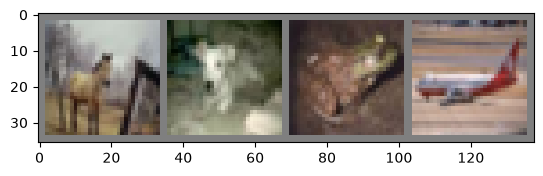

<generator object <genexpr> at 0x121d41fc0>


In [90]:
import matplotlib.pyplot as plt
import numpy as np

def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1,2,0)))
    plt.show()

dataiter = iter(trainloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))
print((f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [91]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3,6,5)
        self.pool = nn.MaxPool2d(2,2)
        self.conv2 = nn.Conv2d(6,16,5)
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x,1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

net = Net()

In [92]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimzer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [93]:
for epoch in range(2):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i & 2000 == 1999:
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished')

Finished


In [94]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

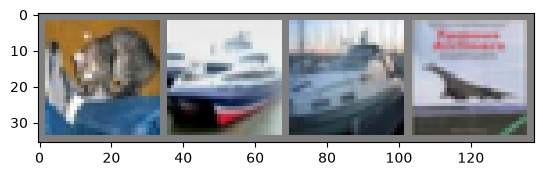

GroundTruth:  cat   ship  ship  plane


In [95]:
dataiter = iter(testloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

In [96]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

In [97]:
outputs = net(images)

In [98]:
a, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

Predicted:  horse horse horse horse


In [99]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)

        b, predicted = torch.max(outputs, 1)
        total += lables.size(0)
        correct += (predicted == labels).sum().item()

print('Accurcay:', 100*correct // total)


Accurcay: 9


In [100]:
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        a, predictions = torch.max(outputs, 1)

        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1

for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 3.8 %
Accuracy for class: car   is 0.0 %
Accuracy for class: bird  is 0.1 %
Accuracy for class: cat   is 0.0 %
Accuracy for class: deer  is 0.0 %
Accuracy for class: dog   is 0.0 %
Accuracy for class: frog  is 0.0 %
Accuracy for class: horse is 95.8 %
Accuracy for class: ship  is 0.0 %
Accuracy for class: truck is 0.0 %


In [103]:
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')
print(device)

mps


In [104]:
net.to(device)

inputs, labels = data[0].to(device), data[1].to(device)

In [105]:
del dataiter